# Propensión a comprar bicicletas: ¿a quién conviene dirigir la campaña de productos de alto margen?

**Proyecto 1 – Machine Learning for Business (2026)** · Dataset 2: *Sales Data* (Kaggle) · Metodología CRISP-DM (Chapman et al., 2000)

Este cuaderno documenta el análisis completo: comprensión del negocio, exploración y preparación de datos, selección y ajuste del modelo, evaluación, interpretación y limitaciones. El pipeline productivo equivalente está en el proyecto Kedro (`kedro run`); aquí se reutilizan sus funciones y sus salidas para que **cuaderno y pipeline no puedan divergir**.

Las citas entre corchetes, p. ej. [Ke et al., 2017], se listan en la sección *Referencias* al final. Todo número que aparece en este cuaderno sale de una celda ejecutada; lo que es supuesto o interpretación se marca como tal.



## 1. Comprensión del negocio

| Elemento | Descripción |
|---|---|
| **Contexto** | Empresa que vende bicicletas, accesorios y ropa de ciclismo en 6 países (EE. UU., Australia, Canadá, Reino Unido, Alemania, Francia). Las bicicletas son solo ~17 % de los pedidos pero generan ~51 % de la ganancia (sección 2.3). |
| **Stakeholder** | Gerencia de Marketing / Ventas Regionales. Decide a qué perfiles de cliente y mercados dirigir campañas de bicicletas (alto ticket) con presupuesto limitado. |
| **Pregunta de negocio** | *Dado el perfil de un cliente (edad, género, ubicación) y el momento del año, ¿qué probabilidad hay de que su compra sea una bicicleta, y qué perfiles conviene priorizar?* |
| **Objetivo analítico** | Clasificación binaria: `is_bike = 1` si la categoría del pedido es *Bikes*. Se entrega una **probabilidad** (para ordenar/priorizar), no solo una etiqueta. |
| **Métrica de éxito técnica** | PR-AUC y ROC-AUC en un conjunto de prueba no visto, mejores que la línea base; **lift** del decil superior (>1.5×). Se prefiere PR-AUC porque la clase positiva es minoritaria [Saito & Rehmsmeier, 2015]. |
| **Métrica de éxito comercial** | Fracción de las compras de bicicleta (y de la ganancia) capturada al contactar solo el *top-k %* según el modelo, frente a contactar al azar (curva de ganancias; Provost & Fawcett, 2013). |
| **Estimación de impacto** | Se reporta de forma descriptiva y sin supuestos inventados: *"contactando al 30 % mejor puntuado se alcanza el X % de las compras de bicicleta, en lugar del 30 % esperable al azar"* (sección 5.3). No se estima ROI en dólares porque el dataset no contiene costos de campaña ni tasas de respuesta. |

**Por qué no se eligió otra pregunta.** Se exploraron y descartaron (con evidencia, sección 2.6): (a) predecir el margen realizado, porque es casi una regla determinista de producto × estado (R² ≈ 0.998) y no aporta aprendizaje; (b) predecir la cantidad por pedido, porque es ruido uniforme dentro de cada categoría (accesorios: 1–32 al azar); (c) pronosticar demanda mensual, porque la serie tiene periodos repetidos, cambios de catálogo y solo ~11 meses con catálogo completo que además se repiten (sección 2.2).

In [1]:
import json, sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
DATA = ROOT / "data"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight"})
BLUE, ORANGE, GRAY = "#2a6f97", "#e07a1f", "#8d99ae"

raw = pd.read_csv(DATA / "01_raw" / "sales_data.csv", parse_dates=["Date"])
print(raw.shape)
raw.head()

(113036, 18)


,Date,Day,Month,Year,Customer_Age,Age_Group,Customer_Gender,Country,State,Product_Category,Sub_Category,Product,Order_Quantity,Unit_Cost,Unit_Price,Profit,Cost,Revenue
0,2013-11-26,26,November,2013,19,Youth (<25),M,Canada,British Columbia,Accessories,Bike Racks,Hitch Rack - 4-Bike,8,45,120,590,360,950
1,2015-11-26,26,November,2015,19,Youth (<25),M,Canada,British Columbia,Accessories,Bike Racks,Hitch Rack - 4-Bike,8,45,120,590,360,950
2,2014-03-23,23,March,2014,49,Adults (35-64),M,Australia,New South Wales,Accessories,Bike Racks,Hitch Rack - 4-Bike,23,45,120,1366,1035,2401
3,2016-03-23,23,March,2016,49,Adults (35-64),M,Australia,New South Wales,Accessories,Bike Racks,Hitch Rack - 4-Bike,20,45,120,1188,900,2088
4,2014-05-15,15,May,2014,47,Adults (35-64),F,Australia,New South Wales,Accessories,Bike Racks,Hitch Rack - 4-Bike,4,45,120,238,180,418


## 2. Comprensión de los datos

El dataset es *Sales Data* (Kaggle, enlace entregado en la guía del curso: <https://www.kaggle.com/datasets/jehanzaibbhatti/sales-data>). Cada fila es una línea de pedido con fecha, perfil del cliente (edad, género), ubicación (país, estado), producto, cantidad, costo, precio, ingreso y ganancia. **No hay identificador de cliente**: cada fila es una transacción, no un cliente (limitación importante, sección 6).

### 2.1 Calidad de datos: faltantes, duplicados, consistencia y atípicos

In [2]:
print("Valores faltantes por columna:\n", raw.isna().sum()[raw.isna().sum() > 0] if raw.isna().any().any() else "ninguno")
dups = raw.duplicated().sum()
print(f"Filas duplicadas exactas: {dups:,} ({dups/len(raw):.2%})")
print("Tras eliminar duplicados:", f"{len(raw.drop_duplicates()):,} filas")
print("Cost != Unit_Cost*Qty :", int((raw.Cost != raw.Unit_Cost*raw.Order_Quantity).sum()))
print("Profit != Revenue-Cost:", int((raw.Profit != raw.Revenue-raw.Cost).sum()))
print("Ganancia negativa     :", int((raw.Profit < 0).sum()), "filas")
q1, q3 = raw.Customer_Age.quantile([.25,.75]); iqr = q3-q1
out = ((raw.Customer_Age > q3+1.5*iqr) | (raw.Customer_Age < q1-1.5*iqr)).sum()
print(f"Edad fuera de 1.5*IQR [Tukey, 1977]: {out} filas; rango de edad {raw.Customer_Age.min()}-{raw.Customer_Age.max()}")
raw.describe().T[["min","50%","max","mean","std"]].round(1)

Valores faltantes por columna:
 ninguno


Filas duplicadas exactas: 1,000 (0.88%)


Tras eliminar duplicados: 112,036 filas
Cost != Unit_Cost*Qty : 0
Profit != Revenue-Cost: 0
Ganancia negativa     : 58 filas
Edad fuera de 1.5*IQR [Tukey, 1977]: 534 filas; rango de edad 17-87


,min,50%,max,mean,std
Date,2011-01-01 00:00:00,2014-06-27 00:00:00,2016-07-31 00:00:00,2014-11-23 12:14:55.063519,NaN
Day,1.0,16.0,31.0,15.665753,8.781567
Year,2011.0,2014.0,2016.0,2014.401739,1.27251
Customer_Age,17.0,35.0,87.0,35.919212,11.021936
Order_Quantity,1.0,10.0,32.0,11.90166,9.561857
Unit_Cost,1.0,9.0,2171.0,267.296366,549.835483
Unit_Price,2.0,24.0,3578.0,452.938427,922.071219
Profit,-30.0,101.0,15096.0,285.051665,453.887443
Cost,1.0,108.0,42978.0,469.318695,884.866118
Revenue,2.0,223.0,58074.0,754.37036,1309.094674


**Decisiones y justificación**

- **Faltantes: ninguno** → no se imputa nada.
- **Duplicados: 1,000 filas exactas → se eliminan.** Son registros idénticos en las 18 columnas (incluida la cantidad). Al quitarlos quedan **112,036 filas**, que coincide con el número de filas que reporta públicamente la versión original del dataset en Kaggle (según una reseña de terceros hallada en línea; no se pudo abrir la página de Kaggle para confirmarlo directamente). Además, **917 de esas 1,000 filas están justo debajo de su original** (copias pegadas, verificado en la celda de consistencia), lo que apoya que fueron inyectadas deliberadamente, consistente con la advertencia de la guía de que *"los datasets no están curados"*.
- **Consistencia aritmética:** `Cost = Unit_Cost × Qty` y `Profit = Revenue − Cost` se cumplen en el 100 % de las filas → no hay errores de captura en esos campos.
- **Atípicos:** las edades extremas (hasta 87) son plausibles, y las ganancias altas corresponden a bicicletas de precio elevado; son **ventas reales, no errores**, por lo que se conservan. Los árboles de gradient boosting son además robustos a valores extremos en los predictores. Las 58 filas de ganancia negativa se conservan (no son predictores ni objetivo).

**Consistencia entre columnas y etiquetas** (cada columna se contrasta contra las demás, no solo se resume):

In [3]:
x = raw.groupby("Product").agg(n_cat=("Product_Category", "nunique"), n_sub=("Sub_Category", "nunique"))
print("Productos con >1 categoría:", int((x.n_cat > 1).sum()), "| con >1 subcategoría:", int((x.n_sub > 1).sum()),
      "| productos con >1 precio o costo:", int(((raw.groupby("Product").Unit_Price.nunique() > 1) | (raw.groupby("Product").Unit_Cost.nunique() > 1)).sum()))
modal = raw.groupby("Product")[["Product_Category", "Sub_Category"]].agg(lambda s: s.value_counts().index[0])
rr = raw.join(modal.add_prefix("modal_"), on="Product")
bad_cat, bad_sub = rr.Product_Category != rr.modal_Product_Category, rr.Sub_Category != rr.modal_Sub_Category
print(f"Filas con categoría distinta a la de su producto: {int(bad_cat.sum())} | con subcategoría distinta: {int(bad_sub.sum())}")
print(f"Filas donde eso cambia 'es bicicleta': {int(((rr.Product_Category == 'Bikes') != (rr.modal_Product_Category == 'Bikes')).sum())}")
display(rr[bad_cat | bad_sub].groupby(["Product", "Product_Category", "modal_Product_Category", "Sub_Category", "modal_Sub_Category"]).size().rename("filas").reset_index())
first = raw.duplicated(keep="first"); prev_same = raw.shift(1).eq(raw).all(axis=1)
print(f"Duplicados exactos que están justo debajo de su original: {int((first & prev_same).sum())} de {int(first.sum())}")
display(raw.groupby("Age_Group").Customer_Age.agg(["min", "max", "count"]))
print("Fecha vs Day/Month/Year inconsistentes:", int(((raw.Date.dt.day != raw.Day) | (raw.Date.dt.year != raw.Year) | (raw.Date.dt.month_name() != raw.Month)).sum()))
print("Estados en más de un país:", int((raw.groupby("State").Country.nunique() > 1).sum()), "| estados con <50 filas:", int((raw.State.value_counts() < 50).sum()), "de", raw.State.nunique())
print("Proporción de pedidos por día de la semana:", raw.Date.dt.dayofweek.value_counts(normalize=True).sort_index().round(3).to_dict())

Productos con >1 categoría: 4 | con >1 subcategoría: 8 | productos con >1 precio o costo: 0


Filas con categoría distinta a la de su producto: 10 | con subcategoría distinta: 24
Filas donde eso cambia 'es bicicleta': 2


,Product,Product_Category,modal_Product_Category,Sub_Category,modal_Sub_Category,filas
0,AWC Logo Cap,Accessories,Clothing,Cleaners,Caps,2
1,Bike Wash - Dissolver,Accessories,Accessories,Fenders,Cleaners,4
2,Fender Set - Mountain,Clothing,Accessories,Gloves,Fenders,4
3,Hitch Rack - 4-Bike,Accessories,Accessories,Bike Stands,Bike Racks,4
4,"Sport-100 Helmet, Black",Accessories,Accessories,Hydration Packs,Helmets,2
5,"Touring-1000 Yellow, 50",Clothing,Bikes,Vests,Touring Bikes,2
6,Water Bottle - 30 oz.,Clothing,Accessories,Caps,Bottles and Cages,2
7,"Women's Mountain Shorts, S",Clothing,Clothing,Socks,Shorts,4


Duplicados exactos que están justo debajo de su original: 917 de 1000


,min,max,count
Age_Group,,,
Adults (35-64),35,64,55824
Seniors (64+),65,87,730
Young Adults (25-34),25,34,38654
Youth (<25),17,24,17828


Fecha vs Day/Month/Year inconsistentes: 0
Estados en más de un país: 0 | estados con <50 filas: 20 de 53
Proporción de pedidos por día de la semana: {0: 0.14, 1: 0.143, 2: 0.141, 3: 0.144, 4: 0.143, 5: 0.146, 6: 0.143}


**Lectura de las comprobaciones entre columnas**

- **Etiquetas de producto corruptas.** Cada producto tiene un único precio y costo, pero **4 productos aparecen con más de una categoría y 8 con más de una subcategoría**: 10 filas con categoría distinta a la de su producto y 24 con subcategoría distinta (p. ej., una bicicleta *Touring-1000 Yellow, 50* etiquetada como *Vests*). Solo **2 filas** cambian el valor de `is_bike`, pero es ruido en la variable objetivo. **Decisión:** asignar a cada fila la categoría y subcategoría mayoritarias de su producto (corregido en `clean_sales`, con prueba automatizada); precio y costo coinciden con el producto, así que el error está en las etiquetas.
- **`Age_Group` es coherente con `Customer_Age`** (la etiqueta *Seniors (64+)* contiene en realidad edades de 65 en adelante; no se usa como predictor).
- **País y estado son coherentes** (ningún estado en dos países), pero **20 de 53 estados tienen menos de 50 filas** (sobre todo en EE. UU.): sus estimaciones son inestables, y por eso las conclusiones por estado solo usan estados con ≥ 500 pedidos.
- **Fechas coherentes** con `Day`/`Month`/`Year` en el 100 % de las filas.
- **Los días de la semana se reparten de forma uniforme (≈14 % cada uno)**: las fechas *exactas* no tienen un patrón comercial real (no hay picos de fin de semana). Eso explica que `day_of_week` y `day_of_month` no aporten nada y se descarten (sección 4.4).

### 2.2 Estructura temporal y filas "gemelas"

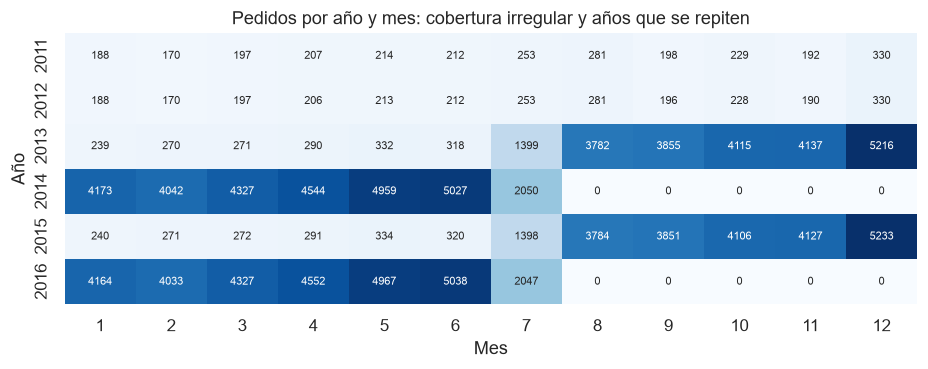

,pedidos,pct_bikes
Date,,
2011,2671,100.0
2012,2664,100.0
2013,24224,23.3
2014,29122,15.6
2015,24227,23.4
2016,29128,15.7


In [4]:
d = raw.drop_duplicates().copy()
d["ym"] = d.Date.dt.to_period("M")
cover = d.pivot_table(index=d.Date.dt.year, columns=d.Date.dt.month, values="Revenue", aggfunc="size").fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(10, 3.2))
sns.heatmap(cover, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 7})
ax.set(xlabel="Mes", ylabel="Año", title="Pedidos por año y mes: cobertura irregular y años que se repiten")
fig.savefig(FIG / "eda_cobertura.png"); plt.show()

by_year = d.groupby(d.Date.dt.year).agg(pedidos=("Revenue","size"), pct_bikes=("Product_Category", lambda s: (s=="Bikes").mean()))
by_year["pct_bikes"] = (by_year.pct_bikes*100).round(1)
by_year

In [5]:
# ¿Los años 2015 y 2016 son "copias" de 2013 y 2014? Se busca la misma llave (día, mes, edad, género, estado, producto).
key = ["Day","Month","Customer_Age","Customer_Gender","State","Product"]
for a, b in [(2013, 2015), (2014, 2016), (2011, 2012)]:
    A, B = d[d.Year == a], d[d.Year == b]
    keysA = set(map(tuple, A[key].values)); keysB = set(map(tuple, B[key].values))
    print(f"{a} vs {b}: filas {len(A):,} / {len(B):,} | llaves de {b} que ya existen en {a}: {len(keysB & keysA)/len(keysB):.1%}")

2013 vs 2015: filas 24,224 / 24,227 | llaves de 2015 que ya existen en 2013: 100.0%


2014 vs 2016: filas 29,122 / 29,128 | llaves de 2016 que ya existen en 2014: 100.0%
2011 vs 2012: filas 2,671 / 2,664 | llaves de 2012 que ya existen en 2011: 100.0%


In [6]:
# Régimen de catálogo: ¿qué categorías se venden en cada mes?
dnd = raw.drop_duplicates().copy(); dnd["bike"] = dnd.Product_Category == "Bikes"
aud = dnd.groupby(dnd.Date.dt.to_period("M")).agg(pedidos=("bike", "size"), pct_bicicleta=("bike", "mean"),
                                                    categorias=("Product_Category", "nunique"), productos=("Product", "nunique"))
aud["pct_bicicleta"] = (aud.pct_bicicleta * 100).round(1)
print("Primera venta por categoría:"); print(dnd.groupby("Product_Category").Date.min().dt.date.to_string())
aud.loc["2013-04":"2014-08"]

Primera venta por categoría:
Product_Category
Accessories    2013-07-01
Bikes          2011-01-01
Clothing       2013-07-01


,pedidos,pct_bicicleta,categorias,productos
Date,,,,
2013-04,290,100.0,1,51
2013-05,332,100.0,1,53
2013-06,318,100.0,1,57
2013-07,1399,36.4,3,123
2013-08,3782,13.0,3,121
2013-09,3855,15.1,3,121
2013-10,4115,14.9,3,125
2013-11,4137,16.7,3,123
2013-12,5216,20.1,3,127


In [7]:
# Aplicación de la limpieza del pipeline (duplicados, etiquetas por producto, solo meses de catálogo estable)
from bike_propensity.pipelines.data_processing.nodes import clean_sales, build_model_input
import yaml
params = yaml.safe_load(open(ROOT / "conf" / "base" / "parameters.yml", encoding="utf-8"))
clean, report = clean_sales(raw, params["data_processing"]["stable_catalog_only"])
print(json.dumps({k: v for k, v in report.items() if k != "months_kept"}, indent=1))
print(f"Meses conservados: {len(report['months_kept'])} -> {report['months_kept'][0]} a {report['months_kept'][10]} y {report['months_kept'][11]} a {report['months_kept'][-1]}")
kept_ym = set(report["months_kept"]); dnd["ym"] = dnd.Date.dt.to_period("M").astype(str)
out_ = dnd[~dnd.ym.isin(kept_ym)]; in_ = dnd[dnd.ym.isin(kept_ym)]
print(f"Filas excluidas por catálogo inestable: {len(out_):,} ({len(out_)/len(dnd):.1%}) con {out_.bike.mean():.1%} de bicicletas | conservadas: {len(in_):,} con {in_.bike.mean():.1%}")
# Deriva dentro de la ventana estable: mezcla de países y edad media por mes (ciclo 2013-14)
w = clean[clean.Date < "2014-08-01"].assign(ym=lambda x: x.Date.dt.to_period("M"))
pd.concat([pd.crosstab(w.ym, w.Country, normalize="index").round(3), w.groupby("ym").Customer_Age.mean().round(1).rename("edad media")], axis=1)

{
 "rows_raw": 113036,
 "missing_values_total": 0,
 "duplicates_removed": 1000,
 "rows_after_dedup": 112036,
 "category_labels_fixed_rows": 10,
 "subcategory_labels_fixed_rows": 24,
 "cost_inconsistent_rows": 0,
 "profit_inconsistent_rows": 0,
 "negative_profit_rows": 58,
 "age_outliers_iqr_rows": 526,
 "rows_before_catalog_filter": 112036,
 "stable_catalog_only": true,
 "rows_clean": 96359
}
Meses conservados: 22 -> 2013-08 a 2014-06 y 2015-08 a 2016-06
Filas excluidas por catálogo inestable: 15,677 (14.0%) con 62.5% de bicicletas | conservadas: 96,359 con 16.6%


,Australia,Canada,France,Germany,United Kingdom,United States,edad media
ym,,,,,,,
2013-08,0.188,0.166,0.096,0.084,0.108,0.358,35.8
2013-09,0.220,0.140,0.097,0.086,0.118,0.339,35.8
2013-10,0.220,0.115,0.073,0.097,0.133,0.362,34.0
2013-11,0.211,0.151,0.081,0.074,0.113,0.369,36.1
2013-12,0.181,0.126,0.106,0.097,0.126,0.365,35.0
2014-01,0.198,0.144,0.093,0.106,0.118,0.341,37.6
2014-02,0.212,0.116,0.113,0.097,0.118,0.344,36.5
2014-03,0.188,0.122,0.107,0.104,0.133,0.345,36.4
2014-04,0.197,0.127,0.111,0.105,0.121,0.339,36.1


**Hallazgos (descriptivos; la causa no está documentada):**

1. **El catálogo cambia durante el periodo.** Accesorios y Ropa **solo existen desde julio de 2013**: de enero de 2011 a junio de 2013 se vendían únicamente bicicletas (≈290–330 pedidos al mes, 100 % bicicletas), julio de 2013 es el mes de lanzamiento (36 % bicicletas) y en **julio de 2014 (y 2016) no hay ninguna bicicleta** (solo 42 productos). Son regímenes de catálogo, no comportamiento del cliente, y distorsionan la tasa de bicicletas y el efecto del mes. **Decisión:** `clean_sales` conserva un mes solo si tiene las 3 categorías *y* el mes anterior también las tenía; esto deja **22 meses** (ago-2013→jun-2014 y su copia ago-2015→jun-2016) y excluye 15,677 filas (14.0 %), que tenían **62.5 % de bicicletas frente a 16.6 %** en las conservadas. La comparación con y sin esta regla está en `experimento_lightgbm.ipynb`.
2. Los años **2012, 2015 y 2016 reproducen el 100 % de las llaves** (día, mes, edad, género, estado, producto) de 2011, 2013 y 2014 respectivamente (verificado arriba), pero con cantidades distintas. El patrón es consistente con datos extendidos sintéticamente. No afirmamos origen, solo que **hay registros casi duplicados entre años**.
3. **2011–2012 solo contienen bicicletas (100 %)** → la variable objetivo sería constante en ese periodo. Lo mismo ocurre en ene–jun de 2013 y de 2015. Todos esos meses quedan excluidos por la regla del punto 1.
4. **Una sola estación observada.** La ventana estable cubre **un único ciclo de 11 meses (agosto→junio)** más su copia, que no es evidencia independiente; **julio nunca aparece**. Por eso el patrón mensual descansa en un solo año y no puede validarse. Además, la composición cambia dentro de la ventana (tabla anterior): por ejemplo, Canadá pasa de 16.6 % de los pedidos en agosto a 11.0 % en junio y la edad media oscila entre 34.0 y 37.6; el modelo incluye país y edad, pero el efecto del mes puede absorber parte de esa deriva.

**Consecuencia metodológica clave:** si se partiera train/test al azar, un pedido "gemelo" de 2013 podría caer en entrenamiento y su gemelo de 2015 en prueba, inflando las métricas (fuga de información; Kaufman et al., 2012). Por eso se usa una **partición por grupos**: todos los gemelos (misma llave *día-mes-edad-género-estado*) quedan del mismo lado. También por esto no se pronostican series de tiempo.

### 2.3 ¿Por qué las bicicletas? Importancia económica por categoría

,pedidos,ganancia_total,ganancia_media,ganancia_mediana,qty_media,% pedidos,% ganancia
Product_Category,,,,,,,
Accessories,64565,8235468,127.6,57.0,15.1,67.0,37.1
Bikes,15990,11363324,710.7,592.0,1.3,16.6,51.1
Clothing,15804,2628888,166.3,70.0,15.1,16.4,11.8


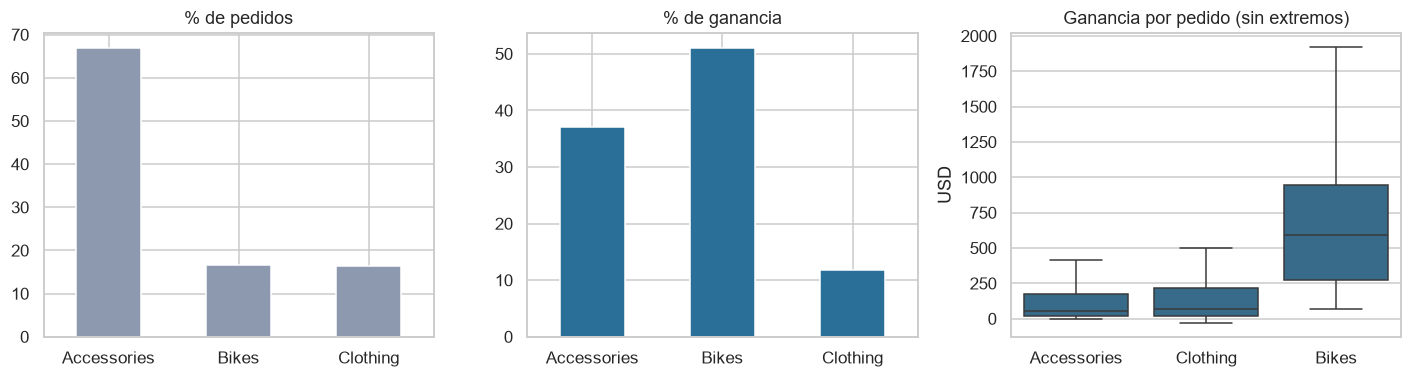

In [8]:
d = clean.copy()
cat = d.groupby("Product_Category").agg(
    pedidos=("Profit", "size"), ganancia_total=("Profit", "sum"),
    ganancia_media=("Profit", "mean"), ganancia_mediana=("Profit", "median"), qty_media=("Order_Quantity", "mean"))
cat["% pedidos"] = (cat.pedidos/cat.pedidos.sum()*100).round(1)
cat["% ganancia"] = (cat.ganancia_total/cat.ganancia_total.sum()*100).round(1)
display(cat.round(1))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
cat["% pedidos"].plot.bar(ax=axes[0], color=GRAY, rot=0, title="% de pedidos")
cat["% ganancia"].plot.bar(ax=axes[1], color=BLUE, rot=0, title="% de ganancia")
sns.boxplot(data=d, x="Product_Category", y="Profit", ax=axes[2], color=BLUE, showfliers=False)
axes[2].set(title="Ganancia por pedido (sin extremos)", xlabel="", ylabel="USD")
for a in axes[:2]: a.set_xlabel("")
fig.tight_layout(); fig.savefig(FIG / "eda_categorias.png"); plt.show()

Las bicicletas son ~17 % de los pedidos pero aportan ~51 % de la ganancia; una bicicleta deja en promedio ≈5.6× la ganancia de un pedido de accesorios (los valores exactos están en la tabla). **Atraer a los perfiles con mayor propensión a comprar bicicletas es, por tanto, la palanca comercial más relevante.** (Aquí el stakeholder paga por priorizar contactos, no por predecir al milímetro.)

### 2.4 ¿Quién compra bicicletas? Exploración del objetivo

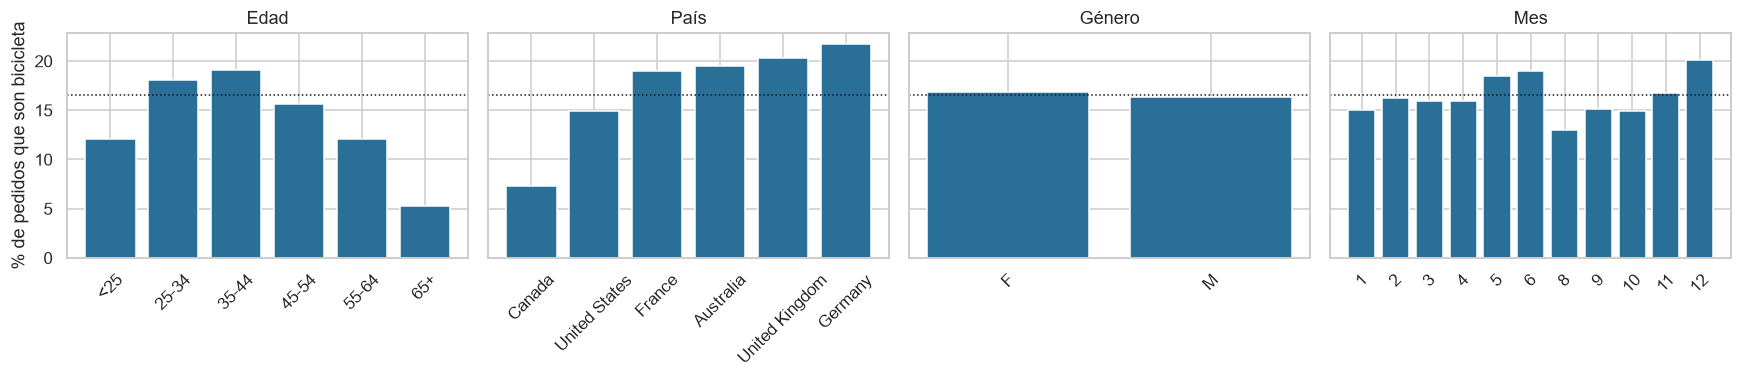

Prevalencia global de bicicletas: 16.6%


In [9]:
d["is_bike"] = (d.Product_Category == "Bikes").astype(int)
d["age_band"] = pd.cut(d.Customer_Age, [16, 24, 34, 44, 54, 64, 100], labels=["<25","25-34","35-44","45-54","55-64","65+"])
d["month"] = d.Date.dt.month
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, col, title in zip(axes, ["age_band","Country","Customer_Gender","month"], ["Edad","País","Género","Mes"]):
    r = d.groupby(col, observed=True).is_bike.mean()
    if col == "Country": r = r.sort_values()
    ax.bar(r.index.astype(str), r.values*100, color=BLUE)
    ax.axhline(d.is_bike.mean()*100, color="k", ls=":", lw=1)
    ax.set(title=title, xlabel="")
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("% de pedidos que son bicicleta")
fig.tight_layout(); fig.savefig(FIG / "eda_target.png"); plt.show()
print(f"Prevalencia global de bicicletas: {d.is_bike.mean():.1%}")

Hay señal pero es **moderada**: los mayores de 64 años compran bicicletas mucho menos; Canadá y EE. UU. menos que el resto; el género casi no discrimina; y el patrón mensual debe tomarse con cautela porque se observa un solo ciclo (sección 2.2). Anticipamos un modelo de poder predictivo modesto, y lo evaluaremos con honestidad.

### 2.5 Hallazgo lateral: el "margen realizado" es una regla, no un fenómeno aleatorio (no se usa como objetivo)

El ingreso por unidad rara vez coincide con el precio de lista: `Revenue / (Unit_Price × Qty)` va de 0.73 a 1.0 y su media depende fuertemente del país. **No sabemos si son descuentos, tipo de cambio o precios locales** (el dataset no lo documenta), así que no lo interpretamos como descuento.

In [10]:
d["price_realization"] = d.Revenue / (d.Unit_Price * d.Order_Quantity)
print(d.groupby("Country").price_realization.agg(["mean","std"]).round(3).sort_values("mean"))

                 mean    std
Country                     
Australia       0.838  0.036
France          0.856  0.060
Germany         0.898  0.060
United States   0.907  0.090
United Kingdom  0.961  0.010
Canada          0.992  0.006


Probamos predecir el margen realizado (`Profit / Revenue`) con *gradient boosting* y validación cruzada agrupada: con producto + estado + país se obtiene **R² ≈ 0.998** (celda de la sección 2.6; en una exploración previa con todas las variables llegó a ≈0.9995), es decir, el margen es prácticamente una tabla de consulta (producto × estado). Un modelo que "acierta" casi perfecto porque redescubre una regla de precios **no responde una pregunta de negocio útil** ni demuestra aprendizaje, y por eso se descartó. Queda como observación para el equipo comercial: el realizado/lista difiere sistemáticamente entre países (p. ej., Canadá ≈ 1 % vs. Australia ≈ 16 % por debajo del precio de lista), lo cual merece una revisión de política de precios, pero requiere documentación de la fuente de datos para interpretarse.

### 2.6 Preguntas descartadas: evidencia
Estas comprobaciones se hicieron durante la exploración con `HistGradientBoosting` y validación cruzada agrupada de 5 pliegues. Se reproducen a continuación para que el lector verifique la decisión.

In [11]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import r2_score
dd = raw.drop_duplicates().reset_index(drop=True)
grp = dd.groupby(["Day","Month","Customer_Age","Customer_Gender","State"]).ngroup()
def cv_r2(X, y):
    X = X.copy()
    for c in X.select_dtypes(["object","string"]): X[c] = X[c].astype("category")
    p = cross_val_predict(HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=0), X, y, cv=GroupKFold(5), groups=grp)
    return r2_score(y, p)
dd["month"] = dd.Date.dt.month
margin = dd.Profit/dd.Revenue
qty_X = dd[["Customer_Age","Customer_Gender","Country","State","month"]]
print(f"(a) R² predecir margen realizado con Producto+Estado+País : {cv_r2(dd[['Product','State','Country']], margin):.4f}  -> casi determinista")
print(f"(b) R² predecir cantidad por pedido con perfil+geografía  : {cv_r2(qty_X, dd.Order_Quantity):.4f}  -> casi nada predecible")
print("    cantidad por categoría (media, min, max):")
print(dd.groupby('Product_Category').Order_Quantity.agg(['mean','min','max']).round(1))

(a) R² predecir margen realizado con Producto+Estado+País : 0.9979  -> casi determinista


(b) R² predecir cantidad por pedido con perfil+geografía  : 0.0113  -> casi nada predecible
    cantidad por categoría (media, min, max):
                  mean  min  max
Product_Category                
Accessories       15.0    1   32
Bikes              1.4    1    4
Clothing          15.0    1   32


## 3. Preparación de los datos

Implementada en el pipeline `data_processing` (`clean_sales`, `build_model_input`):

| Paso | Decisión | Justificación |
|---|---|---|
| Duplicados | Eliminar 1,000 filas exactas | Registros idénticos no aportan información y sesgarían la evaluación. |
| Etiquetas | Categoría y subcategoría = la mayoritaria de cada producto (10 y 24 filas corregidas) | Corrige ruido en la variable objetivo (2 filas cambian `is_bike`). |
| Periodo | Solo meses con catálogo completo y estable (22 meses; 96,359 filas) | Antes de jul-2013 solo hay bicicletas, jul-2013 es el lanzamiento y jul-2014/2016 no tienen bicicletas: otro régimen, no comportamiento del cliente. |
| Objetivo | `is_bike` = categoría `Bikes` | Alinea con la pregunta de negocio. |
| **Predictores permitidos** | Edad, género, país, estado, mes | Son lo que se conoce *del cliente y el contexto* antes de saber qué compra. |
| **Predictores excluidos** | Producto, subcategoría, precios, costos, cantidad, ingreso, ganancia | **Fuga de información**: determinan o son consecuencia de la categoría comprada. |
| Variables de calendario | `month` (numérica). `day_of_week` y `day_of_month` se evaluaron y se descartaron (sección 4.4) | Ablación con CV: sin ellas el AUC es igual o mejor. |
| Categóricas | `OrdinalEncoder` + soporte nativo de categóricas del modelo; categorías no vistas → faltante | Evita el aumento de dimensionalidad de one-hot con ~50 estados y tolera estados nuevos. |
| Agrupación | `split_group` = (día, mes, edad, género, estado) | Mantiene a los "gemelos" del mismo lado de la partición. |

No se escalan variables para el modelo final (los árboles son invariantes a transformaciones monótonas). Para la regresión logística (línea base) se usa *one-hot* + estandarización.

In [12]:
model_input = build_model_input(clean, params["data_processing"]["target_category"], params["data_processing"]["group_columns"])
print("Grupos únicos:", model_input.split_group.nunique(), "| filas:", len(model_input))
model_input.head()

Grupos únicos: 19320 | filas: 96359


,Customer_Age,Customer_Gender,Country,State,month,day_of_week,day_of_month,is_bike,Profit,Year,split_group
0,19,M,Canada,British Columbia,11,1,26,0,590,2013,0
1,19,M,Canada,British Columbia,11,3,26,0,590,2015,0
2,49,M,Australia,New South Wales,3,6,23,0,1366,2014,1
3,49,M,Australia,New South Wales,3,2,23,0,1188,2016,1
4,47,F,Australia,New South Wales,5,3,15,0,238,2014,2


## 4. Modelado

### 4.1 Selección del algoritmo (balance exactitud / velocidad / interpretabilidad)

| Candidato | Por qué sí / por qué no |
|---|---|
| **Línea base trivial** (prevalencia) | Define el piso: ROC-AUC = 0.5. |
| **Regresión logística** | Línea base *interpretable* y rápida; coeficientes explicables; pero asume efectos aditivos y lineales (la edad probablemente no lo es). |
| **Gradient boosting de histogramas** (`HistGradientBoostingClassifier`) — **elegido** | Para datos tabulares con variables mixtas y pocas interacciones, el boosting sobre árboles suele ser el estado del arte práctico [Friedman, 2001; Ke et al., 2017]. La implementación basada en histogramas de scikit-learn (inspirada en LightGBM) entrena 100 mil filas en segundos, maneja categóricas nativamente y faltantes sin imputar [Pedregosa et al., 2011]. |
| Random forest / redes neuronales | No se eligieron: el forest suele dar probabilidades menos calibradas y es más lento a igual desempeño; las redes no aportan ventaja demostrada en tablas pequeñas con 5 variables y son menos interpretables. No se probaron: esta es una justificación a priori, no un resultado empírico. |

**Balance de negocio:** el modelo final se entrena en ~1 minuto, es reproducible, se explica con importancia por permutación y SHAP [Lundberg & Lee, 2017], y se despliega como un único objeto `scikit-learn`. La regresión logística queda como alternativa si el stakeholder priorizara la transparencia total sobre ≈5 puntos de AUC (ver 5.1).

### 4.2 Estrategia de validación
- **Partición 80/20 por grupos** (`GroupShuffleSplit`) para el conjunto de prueba; el test no se toca durante el ajuste.
- **Validación cruzada agrupada de 5 pliegues** (`GroupKFold`) sobre el 80 % de entrenamiento para comparar modelos y ajustar hiperparámetros.
- Intervalos de confianza del 95 % por **bootstrap de grupos** sobre la prueba [Efron & Tibshirani, 1993].

### 4.3 Ajuste de hiperparámetros
Búsqueda aleatoria de 25 configuraciones [Bergstra & Bengio, 2012] sobre tasa de aprendizaje, nº de iteraciones, hojas máximas, muestras mínimas por hoja, regularización L2 y profundidad; criterio: PR-AUC (*average precision*) en CV. Se usa parada temprana. El espacio está en `conf/base/parameters.yml`.

,l2_regularization,learning_rate,max_depth,max_iter,max_leaf_nodes,min_samples_leaf,mean_test_average_precision,std_test_average_precision,rank_test_average_precision,mean_test_roc_auc,std_test_roc_auc,rank_test_roc_auc
0,8.5689,0.0708,NaN,406,14,40,0.2535,0.0036,1,0.6571,0.0070,4
1,0.0153,0.0313,NaN,426,16,363,0.2532,0.0035,2,0.6559,0.0061,12
2,0.0634,0.0207,NaN,415,21,261,0.2529,0.0029,3,0.6562,0.0061,10
3,0.0380,0.0443,6.0,238,58,100,0.2525,0.0033,4,0.6573,0.0060,2
4,0.5408,0.1043,8.0,134,21,100,0.2524,0.0043,5,0.6564,0.0064,8
5,0.0534,0.0440,6.0,269,35,207,0.2520,0.0034,6,0.6564,0.0058,7
6,0.0037,0.1166,NaN,357,31,313,0.2520,0.0044,7,0.6573,0.0060,1
7,0.0013,0.1121,8.0,195,11,241,0.2516,0.0033,8,0.6556,0.0069,14


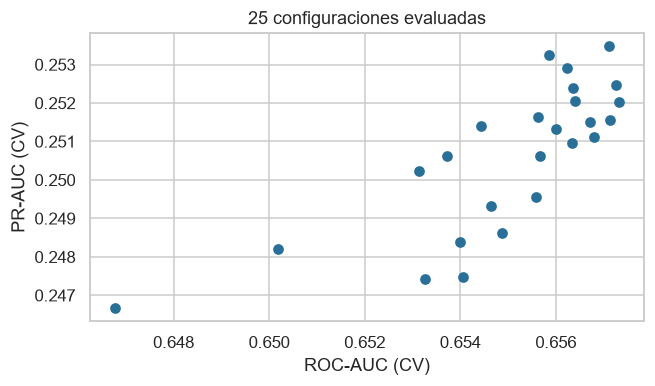

Rango de PR-AUC en CV entre las 25 configuraciones: 0.2467 - 0.2535


In [13]:
cv = pd.read_csv(DATA / "06_models" / "tuning_cv_results.csv")
show = cv.rename(columns=lambda c: c.replace("param_model__", ""))
display(show.head(8).round(4))
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.scatter(cv["mean_test_roc_auc"], cv["mean_test_average_precision"], color=BLUE)
ax.set(xlabel="ROC-AUC (CV)", ylabel="PR-AUC (CV)", title="25 configuraciones evaluadas")
fig.savefig(FIG / "tuning.png"); plt.show()
print(f"Rango de PR-AUC en CV entre las 25 configuraciones: {cv.mean_test_average_precision.min():.4f} - {cv.mean_test_average_precision.max():.4f}")

Las 25 configuraciones dan resultados muy parecidos (el rango de PR-AUC es estrecho): **el desempeño está limitado por la señal disponible en los datos, no por los hiperparámetros**. Es un resultado esperable cuando solo hay 5 predictores y se confirma con la ablación siguiente.

### 4.4 Ablación de variables (solo CV sobre entrenamiento, sin mirar la prueba)

In [14]:
from sklearn.model_selection import cross_validate
from bike_propensity.pipelines.model_training.nodes import make_hgb_pipeline, split_data

train, test = split_data(model_input, params["features"]["group"], params["split"]["test_size"], params["split"]["random_state"])
final = pd.read_pickle(DATA / "06_models" / "final_hgb.pkl")
best = {k: v for k, v in final.named_steps["model"].get_params().items() if k in ["learning_rate","max_iter","max_leaf_nodes","min_samples_leaf","l2_regularization","max_depth"]}

def run(cats, nums, label):
    p = make_hgb_pipeline(cats, nums, 42).set_params(**{f"model__{k}": v for k, v in best.items()})
    r = cross_validate(p, train[cats+nums], train.is_bike, groups=train.split_group, cv=GroupKFold(5),
                       scoring=["roc_auc","average_precision"], n_jobs=-1)
    return {"conjunto": label, "ROC-AUC CV": r["test_roc_auc"].mean(), "± ": r["test_roc_auc"].std(), "PR-AUC CV": r["test_average_precision"].mean()}

G, C, S = "Customer_Gender", "Country", "State"
abl = pd.DataFrame([
    run([G,C,S], ["Customer_Age","month","day_of_week","day_of_month"], "Todas (+día de semana, +día del mes)"),
    run([G,C,S], ["Customer_Age","month","day_of_week"], "+ día de semana"),
    run([G,C,S], ["Customer_Age","month"], "Modelo final: género, país, estado, edad, mes"),
    run([C,S], ["Customer_Age","month"], "Sin género"),
    run([S], ["Customer_Age","month"], "Solo estado, edad, mes"),
    run([G,C,S], ["Customer_Age"], "Sin mes"),
])
abl.round(4)

,conjunto,ROC-AUC CV,±,PR-AUC CV
0,"Todas (+día de semana, +día del mes)",0.6506,0.0062,0.2482
1,+ día de semana,0.6552,0.0066,0.2525
2,"Modelo final: género, país, estado, edad, mes",0.6571,0.0070,0.2535
3,Sin género,0.6510,0.0051,0.2488
4,"Solo estado, edad, mes",0.6516,0.0059,0.2499
5,Sin mes,0.6399,0.0056,0.2454


Quitar `day_of_week` y `day_of_month` **no empeora** el modelo (incluso mejora ligeramente) → se descartan por parsimonia. Quitar `month` baja el AUC ≈ 0.017 (0.657 → 0.640) y quitar género ≈ 0.006 (≈ una desviación entre pliegues, 0.006): el género aporta algo, pequeño pero consistente con la importancia por permutación (5.4), por eso se conserva. Estado + edad + mes concentran casi toda la señal.

## 5. Evaluación

### 5.1 Métricas en el conjunto de prueba (19,108 pedidos agrupados, nunca usados para ajustar)

In [15]:
m = json.load(open(DATA / "08_reporting" / "metrics.json"))
cvb = json.load(open(DATA / "06_models" / "baseline_cv_scores.json"))
rows = []
for k, name in [("dummy","Línea base trivial (prevalencia)"),("logreg","Regresión logística"),("hgb","Gradient boosting (final)")]:
    r = m[k]; rows.append({"modelo": name, "ROC-AUC": r["roc_auc"], "PR-AUC": r["pr_auc"], "Brier": r["brier"], "Log-loss": r["log_loss"]})
tab = pd.DataFrame(rows).set_index("modelo")
display(tab.round(4))
print(f"Prevalencia en prueba: {m['prevalence_test']:.3f}  (PR-AUC de un modelo sin información = prevalencia)")
lo1, hi1 = m["hgb"]["roc_auc_ci95"]; lo2, hi2 = m["hgb"]["pr_auc_ci95"]
print(f"IC 95% bootstrap (por grupos) del modelo final -> ROC-AUC [{lo1:.3f}, {hi1:.3f}] | PR-AUC [{lo2:.3f}, {hi2:.3f}]")
print("Hiperparámetros elegidos:", m["hgb_best_params"])

,ROC-AUC,PR-AUC,Brier,Log-loss
modelo,,,,
Línea base trivial (prevalencia),0.5000,0.1622,0.1359,0.4434
Regresión logística,0.5993,0.2080,0.1336,0.4338
Gradient boosting (final),0.6636,0.2481,0.1300,0.4180


Prevalencia en prueba: 0.162  (PR-AUC de un modelo sin información = prevalencia)
IC 95% bootstrap (por grupos) del modelo final -> ROC-AUC [0.654, 0.675] | PR-AUC [0.237, 0.260]
Hiperparámetros elegidos: {'l2_regularization': 8.568869785189005, 'learning_rate': 0.0707922563040456, 'max_depth': None, 'max_iter': 406, 'max_leaf_nodes': 14, 'min_samples_leaf': 40}


**Lectura.** El modelo final mejora de forma **estadísticamente clara** a ambas líneas base (los intervalos de confianza no incluyen 0.5 y el AUC de la regresión logística, 0.599, queda fuera del IC del modelo final), pero **el poder discriminativo es modesto** (AUC ≈ 0.66): predecir qué compra alguien solo con edad, lugar y mes es intrínsecamente difícil. Lo que importa para el negocio es si el *orden* sirve para priorizar, lo que se mide con lift y ganancias (5.3).

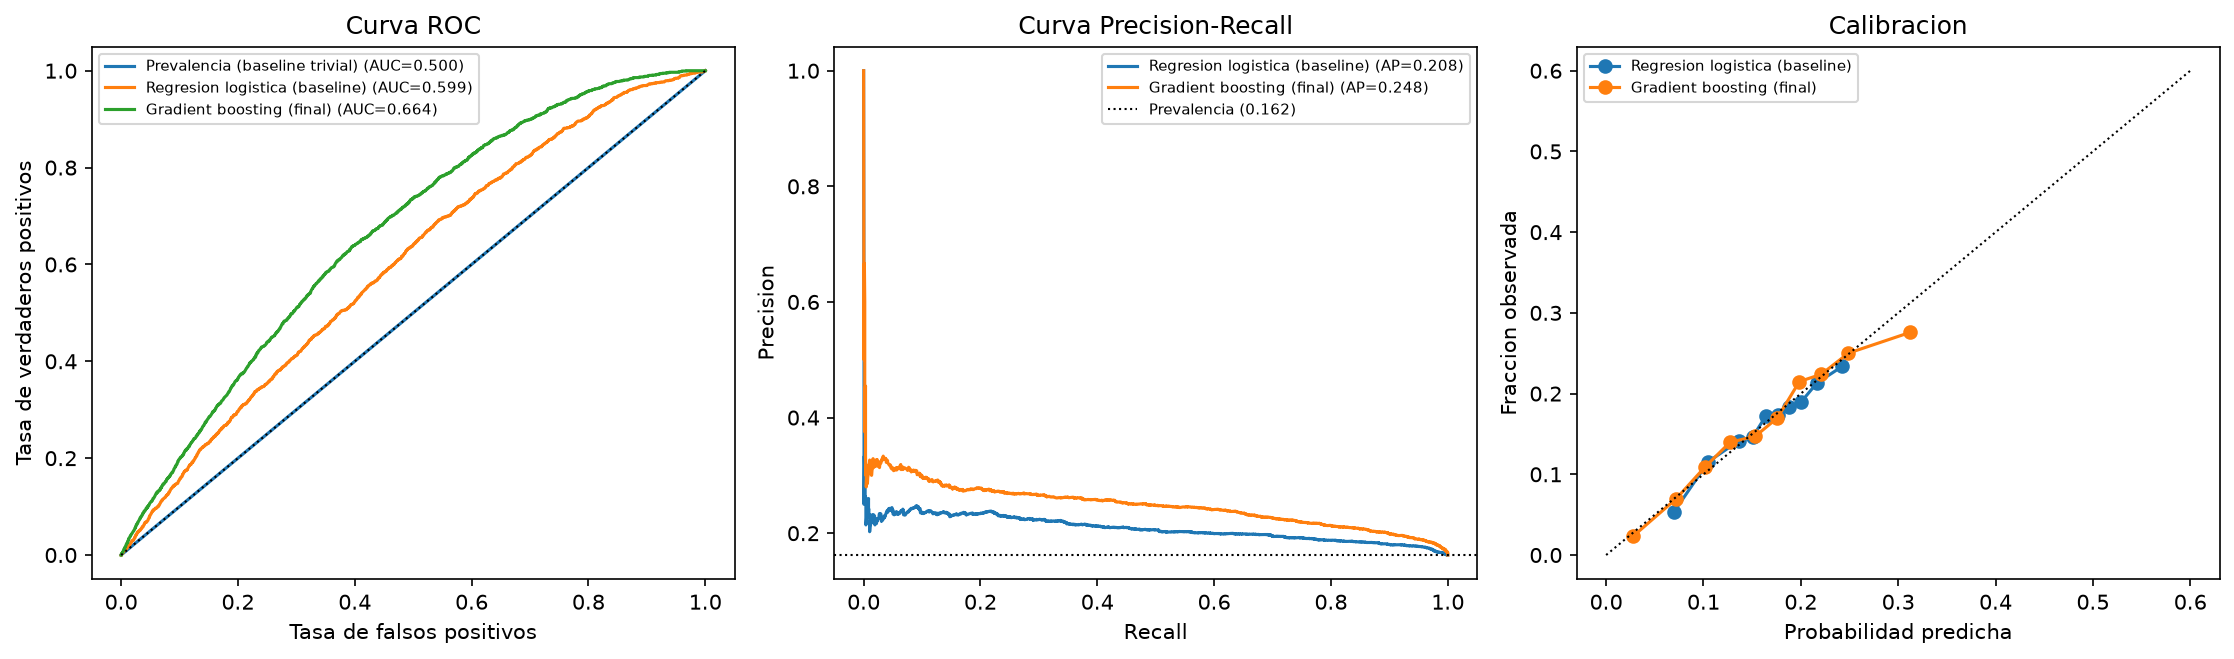

In [16]:
from IPython.display import Image
Image(filename=str(DATA / "08_reporting" / "plots" / "roc_pr_calibration.png"))

**Calibración.** Las probabilidades predichas siguen de cerca la frecuencia observada (curva cerca de la diagonal) [Niculescu-Mizil & Caruana, 2005]; solo el tramo más alto está algo **sobreconfiado** (≈0.31 predicho vs. ≈0.28 observado en el decil superior). Para priorizar (ordenar) no es problema; si se usaran las probabilidades como valores absolutos en un cálculo de ROI convendría recalibrar (p. ej., regresión isotónica).

### 5.2 ¿Es el resultado robusto o está inflado? Chequeo de fuga
- Predictores solo "pre-compra"; ningún campo derivado del producto, precio o cantidad (verificado por prueba automatizada `test_build_model_input_has_no_leaky_columns`).
- Partición por grupos: los registros gemelos nunca se reparten entre entrenamiento y prueba.
- El conjunto de prueba solo se usó para reportar (la ablación y el ajuste usan CV sobre entrenamiento).
- **Resultado de contraste:** en la exploración inicial (CV agrupada, pero **incluyendo 2011–2012** y el año como variable) el AUC fue artificialmente alto (≈0.79), porque ese periodo era 100 % bicicletas y el año lo delataba; al excluirlo el AUC real es ≈0.66. Reportamos el segundo. Esa cifra de 0.79 proviene de una exploración previa no incluida en este cuaderno.

### 5.3 Valor de negocio: lift y curva de ganancias

,decile,n,bike_rate,mean_profit,mean_score,lift
0,1,1911,0.276,266.401,0.312,1.700
1,2,1911,0.250,290.410,0.249,1.542
2,3,1911,0.223,287.511,0.221,1.377
3,4,1910,0.215,270.331,0.198,1.323
4,5,1911,0.170,226.207,0.176,1.048
5,6,1911,0.148,219.105,0.153,0.910
6,7,1910,0.139,222.370,0.127,0.858
7,8,1911,0.109,205.701,0.101,0.671
8,9,1911,0.070,187.222,0.072,0.429
9,10,1911,0.023,129.998,0.027,0.142


,contact_fraction,bike_capture,random_capture,precision,lift,profit_capture,mean_profit_selected,mean_profit_all
0,0.1,0.170,0.1,0.276,1.700,0.115,266.126,230.524
1,0.2,0.324,0.2,0.263,1.621,0.242,278.406,230.524
2,0.3,0.462,0.3,0.250,1.540,0.366,281.483,230.524
3,0.4,0.594,0.4,0.241,1.486,0.484,278.676,230.524
4,0.5,0.699,0.5,0.227,1.398,0.582,268.173,230.524


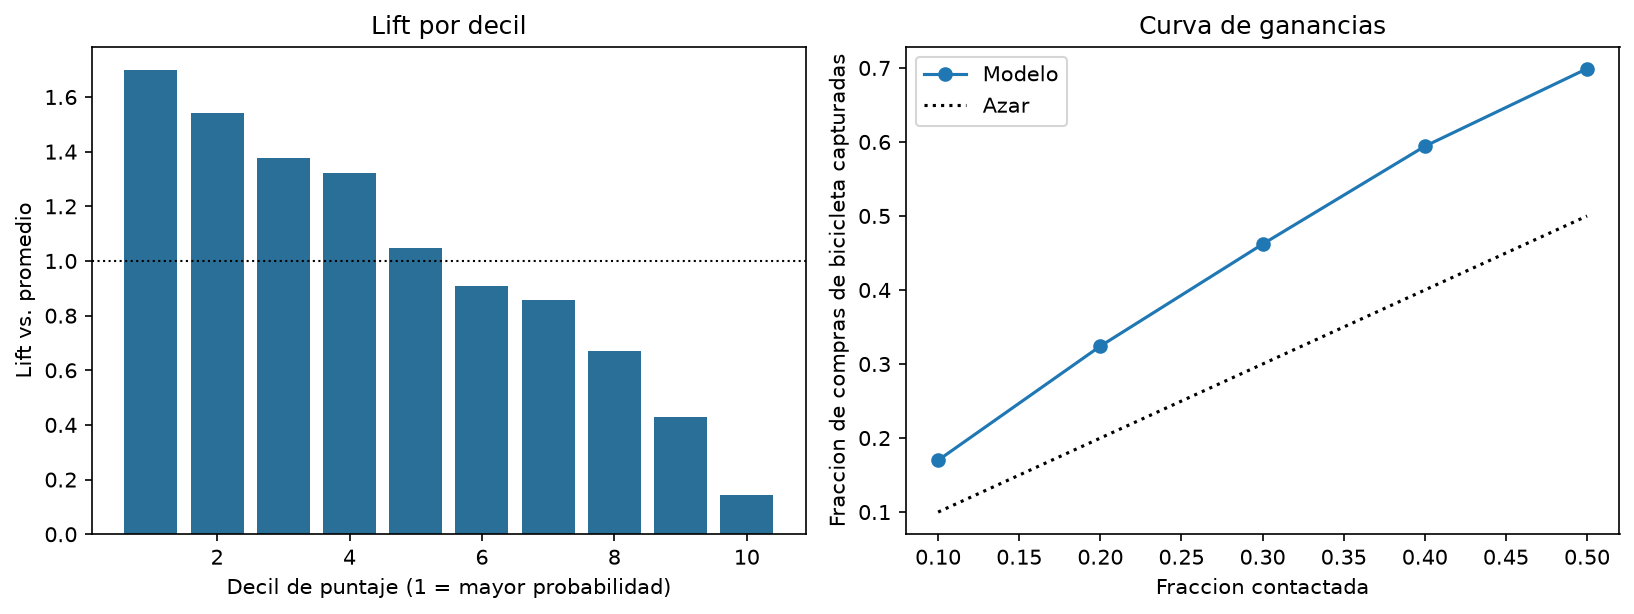

In [17]:
lift = pd.read_csv(DATA / "08_reporting" / "lift_table.csv")
imp = pd.read_csv(DATA / "08_reporting" / "business_impact.csv")
display(lift.round(3))
display(imp.round(3))
Image(filename=str(DATA / "08_reporting" / "plots" / "lift_gains.png"))

**Interpretación para el stakeholder** (todos los números provienen de las tablas anteriores, sobre pedidos de prueba):

- El **decil con mayor puntaje** compra bicicletas ~**1.7×** más que el promedio (27.6 % vs. 16.2 %); el decil más bajo, ~**0.14×** (2.3 %).
- Contactando al **30 %** mejor puntuado se alcanza ≈ **46 %** de las compras de bicicleta (vs. 30 % al azar) y ≈ **37 %** de la ganancia total.
- Al **10 %** superior: ≈17 % de las compras de bicicleta con solo el 10 % de los contactos.
- La ganancia media por pedido en el decil superior (~$266) es ~15 % mayor que la media general (~$231): un beneficio colateral, porque el modelo no ve la ganancia.

> **Alcance de la afirmación.** Son resultados *observacionales* sobre transacciones históricas: muestran qué perfiles *ya compraron* bicicletas, no cuánto aumentarían las ventas si se hace una campaña (eso exigiría un experimento A/B o un modelo de *uplift*).

### 5.4 Interpretación del modelo

,feature,auc_drop_mean,auc_drop_std
0,Customer_Age,0.1007,0.0054
1,State,0.0968,0.0037
2,month,0.0399,0.0024
3,Customer_Gender,0.0081,0.0014
4,Country,0.0035,0.0006


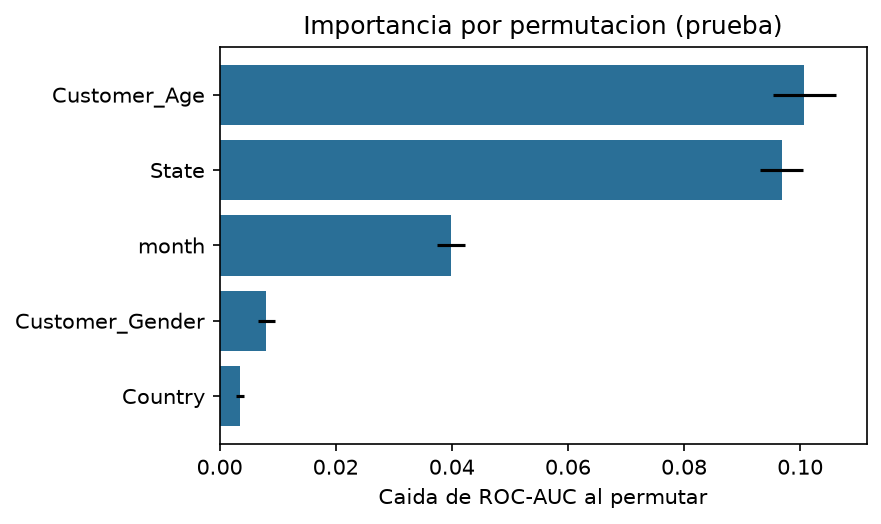

In [18]:
perm = pd.read_csv(DATA / "08_reporting" / "permutation_importance.csv")
display(perm.round(4))
Image(filename=str(DATA / "08_reporting" / "plots" / "permutation_importance.png"))

La **importancia por permutación** [Breiman, 2001; Fisher et al., 2019] (caída de ROC-AUC en prueba al barajar cada variable) indica que **edad, estado y mes** concentran la señal; el género aporta algo pequeño (≈0.008 de AUC) y el país casi nada (el estado ya lo contiene). Como complemento, SHAP [Lundberg & Lee, 2017] muestra la dirección del efecto:

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


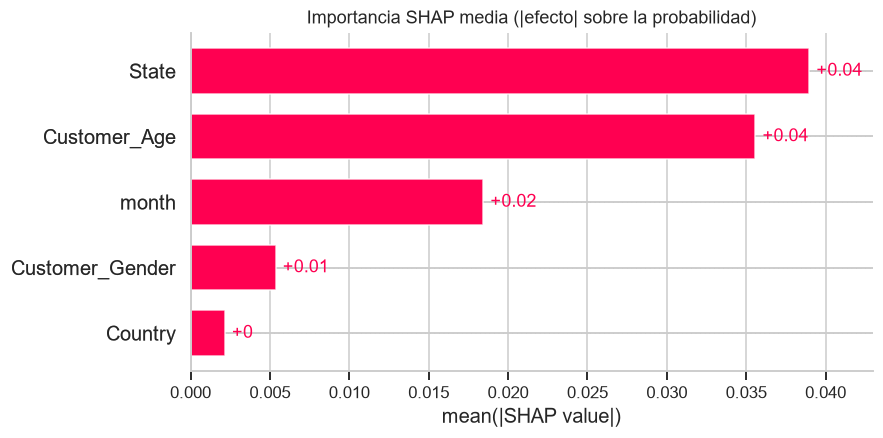

<Figure size 770x396 with 0 Axes>

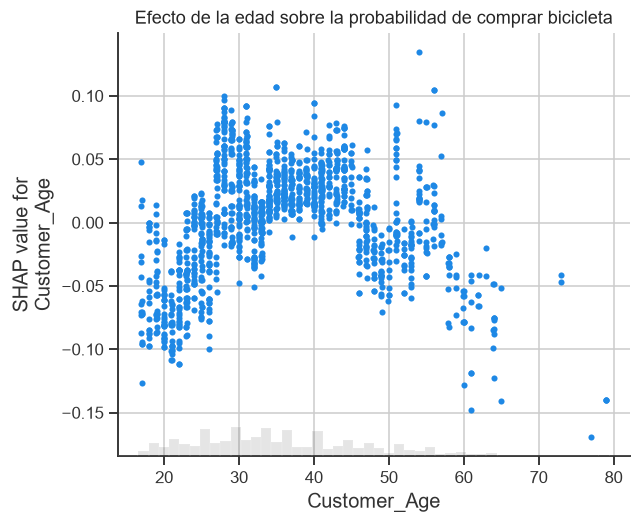

In [19]:
import shap
cols = params["features"]["categorical"] + params["features"]["numeric"]
prep, hgb = final.named_steps["prep"], final.named_steps["model"]
Xt = prep.transform(test[cols]); names = cols
rng = np.random.default_rng(0)
bg = Xt[rng.choice(len(Xt), 200, replace=False)]
samp = Xt[rng.choice(len(Xt), 1500, replace=False)]
f = lambda a: hgb.predict_proba(a)[:, 1]
expl = shap.Explainer(f, bg, feature_names=names, seed=0)
sv = expl(samp, silent=True) if "silent" in expl.__call__.__code__.co_varnames else expl(samp)
fig = plt.figure(figsize=(7, 3.4))
shap.plots.bar(sv, show=False)
plt.title("Importancia SHAP media (|efecto| sobre la probabilidad)")
plt.savefig(FIG / "shap_bar.png", bbox_inches="tight"); plt.show()
fig = plt.figure(figsize=(7, 3.6))
shap.plots.scatter(sv[:, "Customer_Age"], show=False)
plt.title("Efecto de la edad sobre la probabilidad de comprar bicicleta")
plt.savefig(FIG / "shap_age.png", bbox_inches="tight"); plt.show()

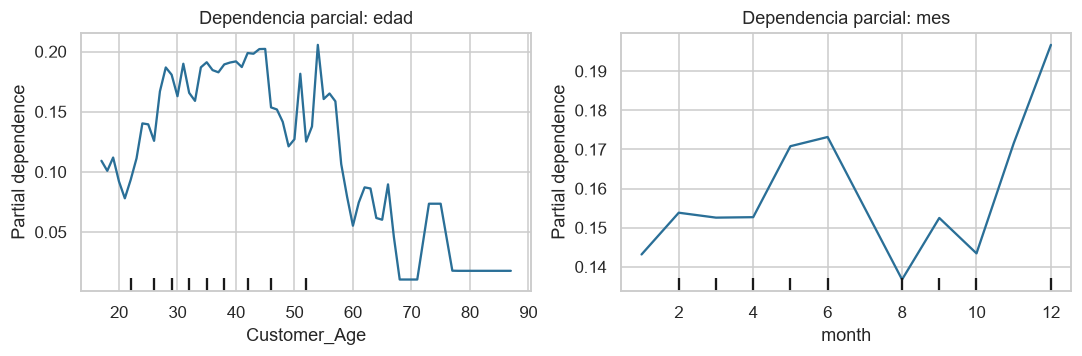

In [20]:
from sklearn.inspection import PartialDependenceDisplay
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
test_f = test[cols].astype({"Customer_Age": float, "month": float})  # PDP exige columnas numericas en float
PartialDependenceDisplay.from_estimator(final, test_f, ["Customer_Age"], ax=ax[0], line_kw={"color": BLUE})
PartialDependenceDisplay.from_estimator(final, test_f, ["month"], ax=ax[1], line_kw={"color": BLUE})
ax[0].set(title="Dependencia parcial: edad", ylabel="P(bicicleta)"); ax[1].set(title="Dependencia parcial: mes", ylabel="")
fig.tight_layout(); fig.savefig(FIG / "pdp.png"); plt.show()

### 5.5 Perfiles accionables: dónde y a quién

Observado en **toda la base limpia** (no solo prueba): tasa de compra de bicicleta por país, por tramo de edad y por estados con volumen suficiente (≥ 500 pedidos para evitar conclusiones sobre muestras pequeñas).

In [21]:
d2 = model_input.copy()
d2["age_band"] = pd.cut(d2.Customer_Age, [16, 24, 34, 44, 54, 64, 100], labels=["<25","25-34","35-44","45-54","55-64","65+"])
pc = d2.groupby("Country").is_bike.agg(["mean","size"]).sort_values("mean", ascending=False)
st = d2.groupby(["Country","State"]).is_bike.agg(["mean","size"]).query("size >= 500").sort_values("mean", ascending=False)
ab = d2.groupby("age_band", observed=True).is_bike.agg(["mean","size"])
print("Tasa global:", round(d2.is_bike.mean(), 3))
display((pc.assign(mean=lambda x: (x['mean']*100).round(1))).rename(columns={"mean":"% bicicleta","size":"pedidos"}))
display((ab.assign(mean=lambda x: (x['mean']*100).round(1))).rename(columns={"mean":"% bicicleta","size":"pedidos"}))
print("Estados con mayor tasa:"); display(st.head(6).assign(mean=lambda x: (x['mean']*100).round(1)).rename(columns={"mean":"% bicicleta","size":"pedidos"}))
print("Estados con menor tasa:"); display(st.tail(6).assign(mean=lambda x: (x['mean']*100).round(1)).rename(columns={"mean":"% bicicleta","size":"pedidos"}))

Tasa global: 0.166


,% bicicleta,pedidos
Country,,
Germany,21.8,9479
United Kingdom,20.4,11753
Australia,19.5,19314
France,19.0,9417
United States,14.9,33928
Canada,7.4,12468


,% bicicleta,pedidos
age_band,,
<25,12.1,15154
25-34,18.1,32614
35-44,19.1,27050
45-54,15.7,15057
55-64,12.1,5842
65+,5.3,642


Estados con mayor tasa:


% bicicleta  pedidos
Country   State                                
Germany   Bayern                  23.9     1226
          Saarland                22.8     2366
Australia South Australia         22.2     1206
Germany   Hessen                  22.0     1989
          Hamburg                 22.0     1558
France    Yveline                 21.2      797

Estados con menor tasa:


% bicicleta  pedidos
Country       State                                  
Australia     Tasmania                  17.4      599
France        Seine Saint Denis         17.1     1450
United States California                16.0    19414
              Washington                13.8     9762
              Oregon                    13.3     4572
Canada        British Columbia           7.3    12412

## 6. Interpretación de negocio, recomendaciones y limitaciones

### Recomendaciones (derivadas de los resultados anteriores)
1. **Usar el puntaje como herramienta de priorización, no como filtro absoluto.** Concentrar la primera ola de la campaña de bicicletas en el 20–30 % de perfiles mejor puntuados (≈32–46 % de las compras de bicicleta capturadas vs. 20–30 % al azar).
2. **Priorizar por edad y ubicación.** Los grupos de 25–44 años y los estados con mayor tasa (sección 5.5: p. ej. Bayern, Saarland, South Australia) concentran la propensión; los mayores de 64 años (5 %), Canadá (7 %) y EE. UU. (15 %) muestran propensión menor, por lo que conviene destinar ahí presupuesto de accesorios/ropa o probar otros mensajes.
3. **No segmentar las campañas por género**: su aporte predictivo es pequeño (≈0.006 de AUC) y segmentar por él añade riesgo de trato desigual.
4. **Validar con un piloto A/B** antes de escalar: medir conversión de la campaña en el grupo de alto puntaje vs. un grupo de control, para estimar el efecto causal y el ROI reales.
5. **Aclarar con el área comercial** la fuente de la diferencia entre ingreso realizado y precio de lista por país (hallazgo lateral 2.5).

### Limitaciones, sesgos y riesgos
- **Señal moderada.** AUC ≈ 0.66 (IC 0.654–0.675): el modelo ordena mejor que el azar pero no "adivina" compras individuales. Con solo 5 variables de perfil, no puede ser mucho mejor; para mejorar harían falta variables de comportamiento (historial, ingresos, canal), que el dataset no tiene.
- **No hay ID de cliente.** Cada fila es una transacción; no se puede modelar *clientes* ni su historial, y un mismo cliente puede aparecer varias veces.
- **Calidad y origen del dataset.** Se detectaron duplicados inyectados, etiquetas de producto corruptas, cambios de catálogo y registros casi duplicados entre años (consistente con extensión sintética). Las conclusiones son válidas *para este dataset*; su aplicación a una empresa real requiere datos reales.
- **Una sola estación observada.** Tras excluir los meses de otro régimen (14 % de las filas), quedan 11 meses (ago→jun) y su copia; julio nunca se observa. El efecto del mes (+0.017 de AUC) descansa en un único ciclo y no puede validarse ni extrapolarse a julio.
- **Sesgo geográfico y demográfico.** El modelo usa edad, género y ubicación. Usarlos para *excluir* grupos de ofertas puede ser discriminatorio o desfavorecer a mercados pequeños; el uso recomendado es **priorizar**, no negar acceso. Los estados con pocos pedidos tienen estimaciones inestables.
- **Observacional, no causal.** El modelo describe asociaciones históricas.
- **Calibración** ligeramente sobreconfiada en el tramo alto (5.1).
- **Deriva.** Si el mix de productos o mercados cambia, el modelo debe reentrenarse (el pipeline Kedro lo permite con un solo comando).

### Conclusión
Con datos limitados a perfil y contexto, un *gradient boosting* bien validado (partición por grupos, sin fuga) logra priorizar clientes con valor claro para el negocio: capturar ≈ 46 % de las compras de bicicleta contactando al 30 % superior. Es un resultado **honesto y modesto**, reproducible con `kedro run`, y con límites explícitos; el siguiente paso recomendado es un piloto A/B.

## Referencias

- Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281–305.
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C., & Wirth, R. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. CRISP-DM Consortium (NCR, SPSS, DaimlerChrysler).
- Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall.
- Fisher, A., Rudin, C., & Dominici, F. (2019). All models are wrong, but many are useful: Learning a variable's importance by studying an entire class of prediction models simultaneously. *Journal of Machine Learning Research, 20*(177), 1–81.
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451
- Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), Article 15. https://doi.org/10.1145/2382577.2382579
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*.
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*. arXiv:1705.07874.
- Niculescu-Mizil, A., & Caruana, R. (2005). Predicting good probabilities with supervised learning. *Proceedings of the 22nd International Conference on Machine Learning (ICML)*, 625–632.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Provost, F., & Fawcett, T. (2013). *Data science for business*. O'Reilly Media.
- Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432
- Tukey, J. W. (1977). *Exploratory data analysis*. Addison-Wesley.
- Bhatti, J. (s. f.). *Sales Data* [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/jehanzaibbhatti/sales-data (enlace proporcionado en la guía del curso; autoría según el nombre de usuario en la URL).
- Kedro (s. f.). *Kedro documentation*. https://docs.kedro.org
- Astral (s. f.). *Ruff documentation*. https://docs.astral.sh/ruff/